# 16 Cross model results and error analysis

One place for the comparison of the four baselines, and the analysis that decides what model 5 should fix.
Everything is computed from the per clip test predictions saved by notebooks 06, 09, 11 and 15, so no model
is trained or re-evaluated here, and every number can be recomputed from the exported files.

**Part 1, results.** The main table (mean ± std over the three reporting seeds, with and without
augmentation) and a per seed supplementary table. Li et al. (2024) and the no motion probe are shown as
reference rows. Both tables are written to CSV for the paper.

**Part 2, where each model fails.** Per class F1 for every model, then the most confused class pairs, and
whether the models confuse the *same* pairs. Shared confusions point to ambiguity in the data or labels,
which no architecture will fix. Confusions that differ between models are the architecture dependent ones,
and are where a better model could gain.

**Part 3, what predicts an error.** Test accuracy by clip length, by the confidence of the hitting wrist
(the wrist that moves most, since the pose model is least reliable there), by player size, and by match
against drill footage. If errors concentrate in one of these, that is a design target for model 5.

**Diagnostic, not a result.** Part 2 also counts how many clips each model gets right, to see whether the
models fail on the same clips. That is an analysis of the baselines. No combination of models is reported as
a result anywhere in this project.

Logs to `BadmintonPoseAnalysis/results`; CSV exports to `/workspace/outputs/results/`.

In [1]:
import glob
import os
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_recall_fscore_support
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
EXPORT = f"{OUTPUTS}/results"
os.makedirs(EXPORT, exist_ok=True)
sys.path.insert(0, REPO)
import dataset as ds

MODELS = ["stgcn", "lstm", "transformer", "sttr"]
LABEL = {"stgcn": "ST-GCN", "lstm": "LSTM", "transformer": "Transformer", "sttr": "ST-TR"}
COLOUR = {"stgcn": "#55a868", "lstm": "#8172b3", "transformer": "#937860", "sttr": "#4c72b0"}
HEADLINE = "advanced"
RUN_RE = re.compile(r"^(stgcn|lstm|transformer|sttr)_(advanced|none)_s(\d+)$")
RARE_THRESHOLD = int(os.environ.get("RARE_THRESHOLD", 150))
N_BOOT, SEED = 1000, 0
LI_ET_AL = {"top1": 0.7441, "top5": 0.9376, "mca": 0.6144}
NO_MOTION_PROBE = {"top1": 0.549, "mca": 0.429}
rng = np.random.RandomState(SEED)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
task = Task.init(project_name="BadmintonPoseAnalysis/results", task_name="cross_model_analysis",
                 task_type=Task.TaskTypes.qc, tags=["analysis", "cross_model"], reuse_last_task_id=False,
                 auto_connect_frameworks={"matplotlib": False})
task.connect({"headline_condition": HEADLINE, "rare_threshold": RARE_THRESHOLD, "bootstrap": N_BOOT})
logger = task.get_logger()


def publish(fig, title):
    logger.report_matplotlib_figure(title, "analysis", figure=fig, iteration=0, report_interactive=False)
    plt.show()


def publish_table(df, title, export=None):
    logger.report_table(title, "analysis", iteration=0, table_plot=df)
    if export:
        df.to_csv(f"{EXPORT}/{export}.csv", index=False)
    return df

ClearML Task: created new task id=f4aa2c2cfe8040ccb278b5ec1caaa4f6
2026-10-06 11:02:55,788 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/b58b0baede1f4527b9f5e9bdceb07833/tasks/f4aa2c2cfe8040ccb278b5ec1caaa4f6/output/log


In [2]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", min_native_frames=5)
class_names = sorted(manifest["class_name"].unique())
K = len(class_names)
cid = {c: i for i, c in enumerate(class_names)}
short = [c.split("_", 1)[1] for c in class_names]
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
rare_ids = [cid[c] for c in class_names if train_counts[c] < RARE_THRESHOLD]
common_ids = [cid[c] for c in class_names if train_counts[c] >= RARE_THRESHOLD]

found = {}
for p in glob.glob(f"{OUTPUTS}/models/**/*_predictions.csv", recursive=True):
    m = RUN_RE.match(os.path.basename(p).replace("_predictions.csv", ""))
    if m:
        found.setdefault((m.group(1), m.group(2)), {})[int(m.group(3))] = p

pred = {}
for (model, cond), seeds in found.items():
    runs = []
    for s, p in sorted(seeds.items()):
        d = pd.read_csv(p)
        d = d[d["split"] == "test"].sort_values("filepath").reset_index(drop=True)
        runs.append({"filepath": d["filepath"].to_numpy(), "label": d["label"].map(cid).to_numpy(),
                     "pred": d["pred"].map(cid).to_numpy(),
                     "top5": np.array([l in str(t).split(";") for l, t in zip(d["label"], d["top5"].fillna(""))]), "seed": s})
    assert all((r["filepath"] == runs[0]["filepath"]).all() for r in runs), f"clip order differs for {model} {cond}"
    pred[(model, cond)] = {"filepath": runs[0]["filepath"], "label": runs[0]["label"], "seeds": [r["seed"] for r in runs],
                           "pred": np.stack([r["pred"] for r in runs]), "top5": np.stack([r["top5"] for r in runs])}

missing = [(m, c) for m in MODELS for c in ("advanced", "none") if (m, c) not in pred]
assert not missing, f"missing runs: {missing}"
files = pred[("stgcn", HEADLINE)]["filepath"]
labels = pred[("stgcn", HEADLINE)]["label"]
assert all((pred[k]["label"] == labels).all() for k in pred)
print({f"{LABEL[m]} {c}": len(pred[(m, c)]["seeds"]) for m in MODELS for c in ("advanced", "none")}, "seeds | test clips:", len(labels))

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
{'ST-GCN advanced': 3, 'ST-GCN none': 3, 'LSTM advanced': 3, 'LSTM none': 3, 'Transformer advanced': 3, 'Transformer none': 3, 'ST-TR advanced': 3, 'ST-TR none': 3} seeds | test clips: 782


## Part 1: results

In [3]:
def seed_row(model, cond, i):
    p = pred[(model, cond)]
    y, yh = p["label"], p["pred"][i]
    rec = np.array([(yh[y == k] == k).mean() for k in range(K)])
    return {"model": LABEL[model], "condition": cond, "seed": p["seeds"][i], "top1": (yh == y).mean(),
            "top5": p["top5"][i].mean(), "mca": rec.mean(),
            "macro_f1": f1_score(y, yh, average="macro", labels=list(range(K)), zero_division=0),
            "limited sample recall": rec[rare_ids].mean(), "common recall": rec[common_ids].mean()}


per_seed = pd.DataFrame([seed_row(m, c, i) for m in MODELS for c in ("advanced", "none") for i in range(len(pred[(m, c)]["seeds"]))])
metric_cols = ["top1", "top5", "mca", "macro_f1", "limited sample recall", "common recall"]

g = per_seed.groupby(["model", "condition"], sort=False)
main = pd.DataFrame({c: [f"{100 * a.mean():.2f} ± {100 * a.std(ddof=1):.2f}" for _, a in g[c]] for c in metric_cols},
                    index=[f"{m}, {c}" for (m, c), _ in g]).reset_index().rename(columns={"index": "model, augmentation"})
refs = pd.DataFrame([
    {"model, augmentation": "Li et al. (2024) ST-GCN", "top1": "74.41", "top5": "93.76", "mca": "61.44", "macro_f1": "", "limited sample recall": "", "common recall": ""},
    {"model, augmentation": "no motion probe (random forest)", "top1": "54.90", "top5": "", "mca": "42.90", "macro_f1": "", "limited sample recall": "", "common recall": ""}])
publish_table(pd.concat([main, refs], ignore_index=True), "main results, test (mean ± std over seeds)", export="main_results")
publish_table(per_seed.assign(**{c: (100 * per_seed[c]).round(2) for c in metric_cols}), "per seed results, test", export="per_seed_results")
pd.concat([main, refs], ignore_index=True)

,"model, augmentation",top1,top5,mca,macro_f1,limited sample recall,common recall
0,"ST-GCN, advanced",72.29 ± 1.06,94.37 ± 0.13,61.21 ± 1.33,62.31 ± 1.94,52.18 ± 2.54,68.44 ± 1.33
1,"ST-GCN, none",71.95 ± 0.63,94.25 ± 0.68,58.65 ± 2.83,60.72 ± 2.65,45.69 ± 5.54,69.01 ± 0.90
2,"LSTM, advanced",69.52 ± 1.03,93.09 ± 0.59,57.94 ± 0.20,59.09 ± 0.16,48.57 ± 3.33,65.44 ± 2.56
3,"LSTM, none",68.97 ± 0.58,93.39 ± 0.77,56.40 ± 2.25,58.13 ± 1.99,46.36 ± 5.78,64.44 ± 1.68
4,"Transformer, advanced",68.20 ± 1.54,92.16 ± 0.15,54.98 ± 1.86,55.75 ± 2.07,45.26 ± 1.78,62.76 ± 2.02
5,"Transformer, none",67.43 ± 0.32,92.75 ± 0.91,57.05 ± 2.41,56.41 ± 1.75,50.65 ± 4.30,62.17 ± 1.02
6,"ST-TR, advanced",68.76 ± 0.30,91.47 ± 1.19,56.11 ± 1.44,57.08 ± 1.50,46.33 ± 3.02,63.94 ± 0.66
7,"ST-TR, none",68.88 ± 1.29,89.60 ± 0.64,55.70 ± 2.16,57.45 ± 2.35,45.66 ± 2.87,63.73 ± 1.80
8,Li et al. (2024) ST-GCN,74.41,93.76,61.44,,,
9,no motion probe (random forest),54.90,,42.90,,,


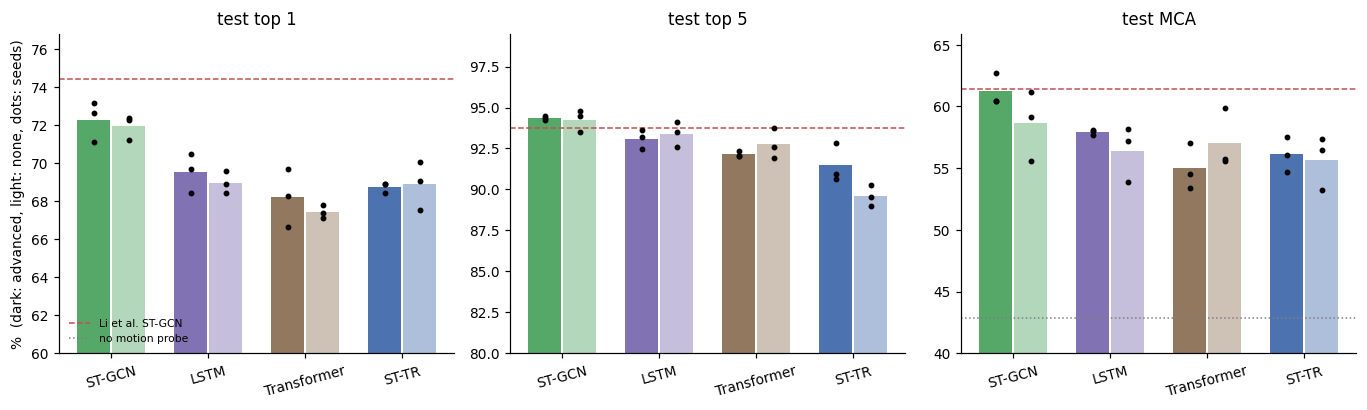

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
for ax, m_, title in zip(axes, ["top1", "top5", "mca"], ["test top 1", "test top 5", "test MCA"]):
    for j, model in enumerate(MODELS):
        for k, cond in enumerate(["advanced", "none"]):
            vals = 100 * per_seed[(per_seed["model"] == LABEL[model]) & (per_seed["condition"] == cond)][m_].to_numpy()
            x = j + (k - 0.5) * 0.36
            ax.bar(x, vals.mean(), width=0.34, color=COLOUR[model], alpha=1.0 if cond == "advanced" else 0.45)
            ax.scatter(np.full(len(vals), x), vals, color="black", s=8, zorder=3)
    if m_ in LI_ET_AL:
        ax.axhline(100 * LI_ET_AL[m_], color="#c44e52", ls="--", lw=1, label="Li et al. ST-GCN")
    if m_ in NO_MOTION_PROBE:
        ax.axhline(100 * NO_MOTION_PROBE[m_], color="grey", ls=":", lw=1, label="no motion probe")
    ax.set_xticks(range(len(MODELS)), [LABEL[m] for m in MODELS], rotation=15)
    ax.set_title(title)
    ax.set_ylim(40 if m_ == "mca" else 60 if m_ == "top1" else 80, None)
axes[0].set_ylabel("%  (dark: advanced, light: none, dots: seeds)")
axes[0].legend(frameon=False, fontsize=7, loc="lower left")
fig.tight_layout()
publish(fig, "model comparison")

## Part 2: where each model fails

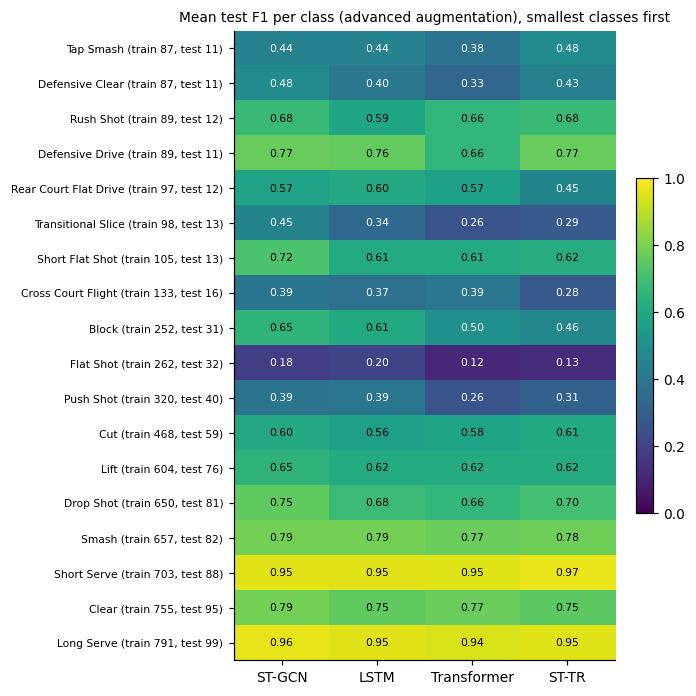

,class,ST-GCN,LSTM,Transformer,ST-TR
0,Short Serve,0.954,0.954,0.950,0.970
1,Cross Court Flight,0.387,0.368,0.392,0.278
2,Lift,0.648,0.616,0.616,0.616
3,Tap Smash,0.440,0.444,0.383,0.482
4,Block,0.649,0.607,0.502,0.460
5,Drop Shot,0.755,0.680,0.663,0.703
6,Push Shot,0.386,0.392,0.260,0.312
7,Transitional Slice,0.448,0.343,0.260,0.286
8,Cut,0.602,0.565,0.580,0.606
9,Rush Shot,0.675,0.590,0.657,0.675


In [5]:
def per_class_f1(model, cond):
    p = pred[(model, cond)]
    out = []
    for yh in p["pred"]:
        _, _, f, _ = precision_recall_fscore_support(p["label"], yh, labels=list(range(K)), zero_division=0)
        out.append(f)
    return np.mean(out, axis=0)


f1 = pd.DataFrame({LABEL[m]: per_class_f1(m, HEADLINE) for m in MODELS}, index=short)
order = np.argsort(train_counts.to_numpy())
test_n = pd.Series(labels).value_counts().reindex(range(K)).to_numpy()

fig, ax = plt.subplots(figsize=(6.4, 6.4))
im = ax.imshow(f1.iloc[order].values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(MODELS)), [LABEL[m] for m in MODELS])
ax.set_yticks(range(K), [f"{short[i]} (train {train_counts.iloc[i]}, test {test_n[i]})" for i in order], fontsize=7)
for r in range(K):
    for c in range(len(MODELS)):
        v = f1.iloc[order].values[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v < 0.55 else "black")
ax.set_title(f"Mean test F1 per class ({HEADLINE} augmentation), smallest classes first", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
publish(fig, "per class F1 by model")
publish_table(f1.round(3).reset_index().rename(columns={"index": "class"}), "per class F1 by model", export="per_class_f1")

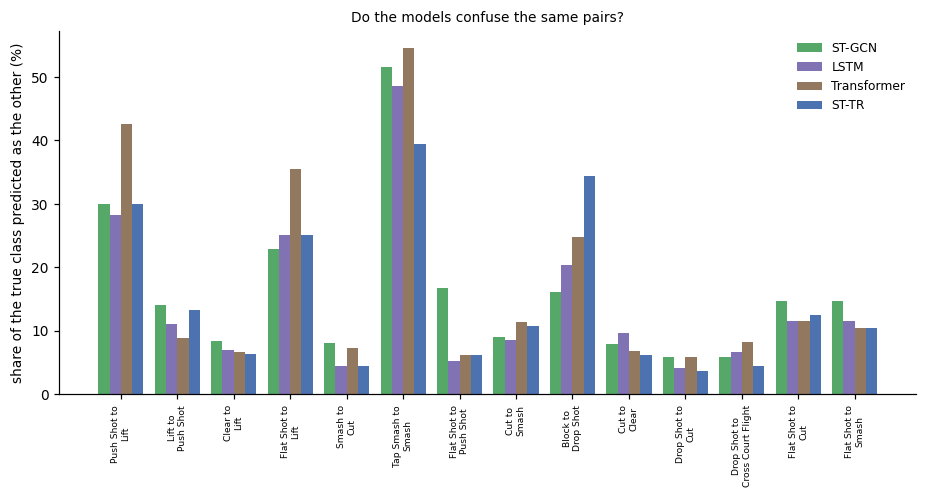

,true class,predicted as,ST-GCN clips per seed,ST-GCN rate (%),LSTM rate (%),Transformer rate (%),ST-TR rate (%)
0,Push Shot,Lift,12.0,30.0,28.3,42.5,30.0
1,Lift,Push Shot,10.7,14.0,11.0,8.8,13.2
2,Clear,Lift,8.0,8.4,7.0,6.7,6.3
3,Flat Shot,Lift,7.3,22.9,25.0,35.4,25.0
4,Smash,Cut,6.7,8.1,4.5,7.3,4.5
5,Tap Smash,Smash,5.7,51.5,48.5,54.5,39.4
6,Flat Shot,Push Shot,5.3,16.7,5.2,6.2,6.2
7,Cut,Smash,5.3,9.0,8.5,11.3,10.7
8,Block,Drop Shot,5.0,16.1,20.4,24.7,34.4
9,Cut,Clear,4.7,7.9,9.6,6.8,6.2


In [6]:
def mean_confusion(model, cond):
    p = pred[(model, cond)]
    cm = np.zeros((K, K))
    for yh in p["pred"]:
        np.add.at(cm, (p["label"], yh), 1)
    return cm / len(p["pred"])           # mean clips per seed


cms = {m: mean_confusion(m, HEADLINE) for m in MODELS}
row_n = cms["stgcn"].sum(axis=1)
rate = {m: cms[m] / row_n[:, None] for m in MODELS}

off = cms["stgcn"].copy()
np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:14], off.shape))[0]
pairs = pd.DataFrame([{"true class": short[i], "predicted as": short[j], "ST-GCN clips per seed": round(off[i, j], 1),
                       **{f"{LABEL[m]} rate (%)": round(100 * rate[m][i, j], 1) for m in MODELS}} for i, j in top])
publish_table(pairs, "most confused class pairs (ST-GCN) and the same pairs in every model", export="confusion_pairs")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
x = np.arange(len(pairs))
for k, m in enumerate(MODELS):
    ax.bar(x + (k - 1.5) * 0.2, pairs[f"{LABEL[m]} rate (%)"], width=0.2, color=COLOUR[m], label=LABEL[m])
ax.set_xticks(x, [f"{a} to\n{b}" for a, b in zip(pairs["true class"], pairs["predicted as"])], fontsize=6, rotation=90)
ax.set_ylabel("share of the true class predicted as the other (%)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Do the models confuse the same pairs?", fontsize=9)
fig.tight_layout()
publish(fig, "shared confusions")
pairs

In [7]:
corr = {m: (pred[(m, HEADLINE)]["pred"] == labels).mean(axis=0) >= 0.5 for m in MODELS}      # majority of seeds right
n_right = sum(c.astype(int) for c in corr.values())
dist = pd.DataFrame({"models right": range(5), "clips": [(n_right == k).sum() for k in range(5)]})
dist["share (%)"] = (100 * dist["clips"] / len(labels)).round(1)
only_other = (~corr["stgcn"]) & (n_right >= 1)
by_class = pd.DataFrame({"class": short, "ST-GCN wrong, another model right": [int((only_other & (labels == k)).sum()) for k in range(K)],
                         "all four wrong": [int(((n_right == 0) & (labels == k)).sum()) for k in range(K)],
                         "test clips": test_n}).sort_values("all four wrong", ascending=False)
publish_table(dist, "how many of the four models get each test clip right (diagnostic)", export="clip_agreement")
publish_table(by_class.head(10), "classes with the most clips every model gets wrong")
print(f"all four wrong: {dist.loc[0, 'clips']} clips ({dist.loc[0, 'share (%)']}%); "
      f"ST-GCN wrong but at least one other right: {int(only_other.sum())} clips")
dist

all four wrong: 141 clips (18.0%); ST-GCN wrong but at least one other right: 69 clips


,models right,clips,share (%)
0,0,141,18.0
1,1,67,8.6
2,2,47,6.0
3,3,68,8.7
4,4,459,58.7


## Part 3: what predicts an error

Properties are computed from the saved keypoints for the test clips. The hitting wrist is the wrist that
travels furthest during the clip. Numeric properties are split into three equal sized groups (the value range
of each is in the exported table). Intervals are bootstrap intervals over test clips, so with about 260 clips
per group they are roughly plus or minus 5 points; only large differences are meaningful. Clip length is
entangled with class (smashes are short, long serves are long), so a length effect may really be a class effect.

In [8]:
log = pd.read_csv(f"{DATA}/extraction_log.csv").set_index("filepath")
rows = []
for fp in files:
    cls = fp.split("/")[0]
    stem = os.path.splitext(os.path.basename(fp))[0]
    a = np.load(f"{DATA}/keypoints_interp/{cls}/{stem}.npy")
    travel = [np.linalg.norm(np.diff(a[:, j, :2], axis=0), axis=1).sum() for j in (9, 10)]
    hit = 9 + int(np.argmax(travel))
    height = np.median(a[:, :, 1].max(axis=1) - a[:, :, 1].min(axis=1))
    rows.append({"filepath": fp, "clip length (source frames)": log.loc[fp, "num_frames_total"], "hitting wrist confidence": a[:, hit, 2].mean(),
                 "player height (px)": height, "source": "drill session" if "2023-05-02" in fp else "match"})
props = pd.DataFrame(rows)
props.describe().round(2)

,clip length (source frames),hitting wrist confidence,player height (px)
count,782.0,782.00,782.00
mean,33.1,0.59,139.42
std,12.8,0.12,23.44
min,4.0,0.14,69.27
25%,25.0,0.52,124.50
50%,31.0,0.61,135.61
75%,40.0,0.68,152.14
max,87.0,0.86,258.61


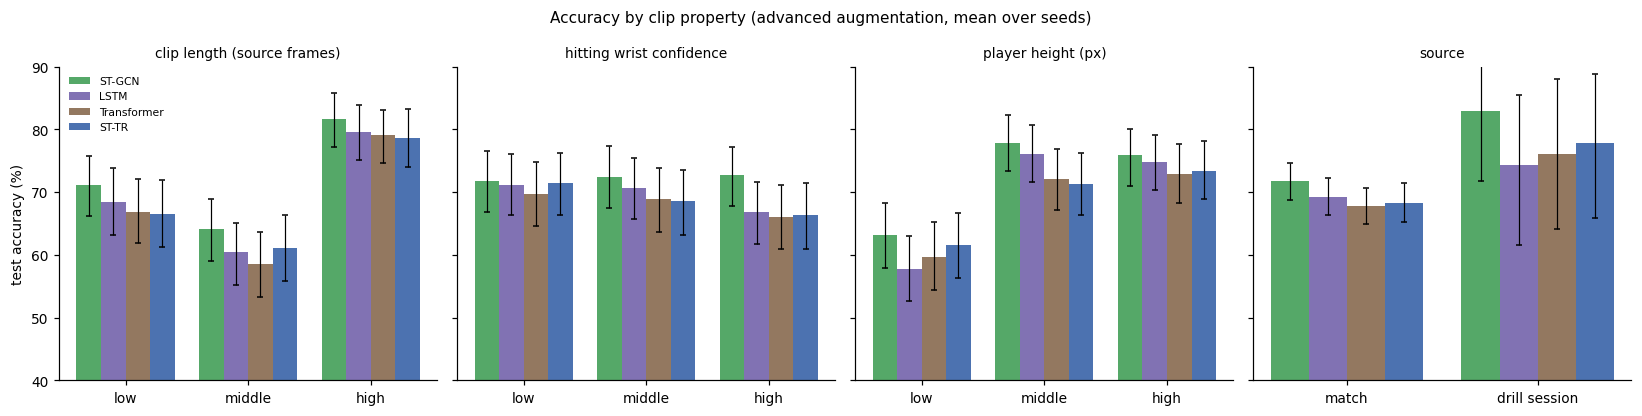

,property,bin,range,clips,model,accuracy (%),95% CI
0,clip length (source frames),low,4 to 27,261,ST-GCN,71.1,"[66.2, 75.7]"
4,clip length (source frames),middle,27 to 36,260,ST-GCN,64.1,"[59.0, 68.8]"
8,clip length (source frames),high,36 to 87,261,ST-GCN,81.6,"[77.1, 85.8]"
12,hitting wrist confidence,low,0.1374 to 0.5501,261,ST-GCN,71.8,"[66.8, 76.5]"
16,hitting wrist confidence,middle,0.5502 to 0.6585,260,ST-GCN,72.4,"[67.4, 77.3]"
20,hitting wrist confidence,high,0.6586 to 0.8597,261,ST-GCN,72.7,"[67.8, 77.3]"
24,player height (px),low,69.27 to 128.5,261,ST-GCN,63.2,"[58.0, 68.3]"
28,player height (px),middle,128.6 to 145,260,ST-GCN,77.8,"[73.3, 82.3]"
32,player height (px),high,145 to 258.6,261,ST-GCN,75.9,"[71.0, 80.1]"
36,source,match,,743,ST-GCN,71.7,"[68.8, 74.7]"


In [9]:
def bootstrap_acc(c, idx, B=N_BOOT):
    s = rng.choice(idx, size=(B, len(idx)))
    return np.percentile(c[s].mean(axis=1), [2.5, 97.5])


clip_correct = {m: (pred[(m, HEADLINE)]["pred"] == labels).mean(axis=0) for m in MODELS}     # per clip, mean over seeds
rows = []
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, prop in zip(axes, ["clip length (source frames)", "hitting wrist confidence", "player height (px)", "source"]):
    if prop == "source":
        bins = props[prop]
        names = ["match", "drill session"]
    else:
        q = pd.qcut(props[prop].rank(method="first"), 3, labels=["low", "middle", "high"])
        bins, names = q, ["low", "middle", "high"]
        spans = props.groupby(q, observed=True)[prop].agg(["min", "max"])
    for j, nm in enumerate(names):
        idx = np.where((bins == nm).to_numpy())[0]
        for k, m in enumerate(MODELS):
            acc = clip_correct[m][idx].mean()
            lo, hi = bootstrap_acc(clip_correct[m], idx)
            ax.bar(j + (k - 1.5) * 0.2, 100 * acc, width=0.2, color=COLOUR[m], label=LABEL[m] if j == 0 else None)
            ax.errorbar(j + (k - 1.5) * 0.2, 100 * acc, yerr=[[100 * (acc - lo)], [100 * (hi - acc)]], color="black", capsize=2, lw=0.8)
            span = "" if prop == "source" else f"{spans.loc[nm, 'min']:.4g} to {spans.loc[nm, 'max']:.4g}"
            rows.append({"property": prop, "bin": nm, "range": span, "clips": len(idx), "model": LABEL[m],
                         "accuracy (%)": round(100 * acc, 1), "95% CI": f"[{100 * lo:.1f}, {100 * hi:.1f}]"})
    ax.set_xticks(range(len(names)), names)
    ax.set_title(prop, fontsize=9)
    ax.set_ylim(40, 90)
axes[0].set_ylabel("test accuracy (%)")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle(f"Accuracy by clip property ({HEADLINE} augmentation, mean over seeds)", fontsize=10)
fig.tight_layout()
publish(fig, "accuracy by clip property")
prop_table = pd.DataFrame(rows)
publish_table(prop_table, "accuracy by clip property", export="accuracy_by_property")
prop_table[prop_table["model"] == "ST-GCN"]

### Is the small player effect just class mix?

Small (far court) players may hit different shots from large ones, so the lower accuracy of the smallest third
could be a class effect rather than a scale effect. To separate the two, the smallest third of players is
compared with what their accuracy would be if each class were played at the accuracy of the other two thirds
(indirect standardisation: the expected accuracy uses the same class mix as the small players). The
difference between observed and expected is the deficit that class mix cannot explain. Intervals resample
test clips within each class.

In [10]:
low = (pd.qcut(props["player height (px)"].rank(method="first"), 3, labels=["low", "middle", "high"]) == "low").to_numpy()
cls_idx = [np.where(labels == k)[0] for k in range(K)]


def standardised_gap(c, rows_by_class):
    obs_num = obs_den = exp_num = 0.0
    for idx in rows_by_class:
        lo_i, re_i = idx[low[idx]], idx[~low[idx]]
        if len(lo_i) == 0 or len(re_i) == 0:
            continue
        obs_num += c[lo_i].sum()
        obs_den += len(lo_i)
        exp_num += len(lo_i) * c[re_i].mean()
    return obs_num / obs_den - exp_num / obs_den, obs_num / obs_den, exp_num / obs_den


rows = []
for m in MODELS:
    c = clip_correct[m]
    gap, obs, exp = standardised_gap(c, cls_idx)
    boots = [standardised_gap(c, [rng.choice(ix, len(ix)) for ix in cls_idx])[0] for _ in range(N_BOOT)]
    lo_ci, hi_ci = np.percentile(boots, [2.5, 97.5])
    rows.append({"model": LABEL[m], "smallest third observed (%)": round(100 * obs, 1),
                 "expected from class mix (%)": round(100 * exp, 1),
                 "raw gap to other two thirds (points)": round(100 * (c[low].mean() - c[~low].mean()), 1),
                 "class adjusted deficit (points)": round(100 * gap, 1), "95% CI": f"[{100 * lo_ci:+.1f}, {100 * hi_ci:+.1f}]"})
adjusted = pd.DataFrame(rows)
publish_table(adjusted, "small player deficit after controlling for class", export="small_player_adjusted")

mix = pd.DataFrame({"class": short, "share of smallest third (%)": [round(100 * (low & (labels == k)).sum() / low.sum(), 1) for k in range(K)],
                    "share of all test clips (%)": [round(100 * (labels == k).mean(), 1) for k in range(K)]})
mix["difference"] = (mix["share of smallest third (%)"] - mix["share of all test clips (%)"]).round(1)
publish_table(mix.sort_values("difference", ascending=False).head(6), "classes over represented among the smallest players")
adjusted

,model,smallest third observed (%),expected from class mix (%),raw gap to other two thirds (points),class adjusted deficit (points),95% CI
0,ST-GCN,63.2,68.8,-13.6,-5.6,"[-13.0, +2.7]"
1,LSTM,57.7,66.6,-17.7,-8.9,"[-17.0, -0.7]"
2,Transformer,59.6,60.6,-12.8,-0.9,"[-9.1, +7.1]"
3,ST-TR,61.6,60.8,-10.8,0.7,"[-7.3, +9.1]"


In [11]:
task.close()
print("exports written to", EXPORT, ":", sorted(os.listdir(EXPORT)))

exports written to /workspace/outputs/results : ['accuracy_by_property.csv', 'clip_agreement.csv', 'confusion_pairs.csv', 'main_results.csv', 'per_class_f1.csv', 'per_seed_results.csv', 'small_player_adjusted.csv']


## Using this for model 5

Read three things off the outputs above before choosing a design.

1. **Which classes, and how many clips, are still wrong for every model.** That number is the ceiling any
   architecture can address. Clips only ST-GCN misses are the room for improvement.
2. **Whether confusions are shared.** If the most confused pairs have similar rates in all four models, the
   confusion is a property of the data, and the right response is analysis and honest reporting rather than
   architecture.
3. **Whether error rises in one clip property.** Low hitting wrist confidence points to a confidence aware
   design; short clips to temporal modelling; small players to scale handling; drill versus match to a
   camera shortcut.

The design for model 5 should be justified by one or two of these findings, stated in the methods, and then
tested like every other model: three seeds, with and without augmentation, against the same baselines.